In [4]:
import time
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

In [5]:
SIZE = 128
BATCH = 32
EPOCHS = 10

(raw_train, raw_val, raw_test), info = tfds.load(
    "oxford_iiit_pet",
    split=["train[:80%]", "train[80%:]", "test"],
    as_supervised=True, with_info=True)
num_classes = info.features["label"].num_classes   # 37

In [6]:
def prepare(img, lbl):
    return tf.image.resize(img, (SIZE, SIZE)), lbl

train_data = (raw_train.map(prepare).shuffle(1000)
              .batch(BATCH).prefetch(tf.data.AUTOTUNE))
val_data = raw_val.map(prepare).batch(BATCH).prefetch(tf.data.AUTOTUNE)
test_data = raw_test.map(prepare).batch(BATCH).prefetch(tf.data.AUTOTUNE)

augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
])


In [7]:
def train_and_report(model, name):
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    t0 = time.time()
    hist = model.fit(train_data, validation_data=val_data,   # Validation بس
                     epochs=EPOCHS, verbose=2)
    secs = time.time() - t0
    # التقييم النهائي على الـ Test مرة واحدة بس
    loss, acc = model.evaluate(test_data, verbose=0)
    print(f"\n[{name}] final TEST acc = {acc:.3f} | loss = {loss:.3f} "
          f"| time = {secs/60:.1f} min | params = {model.count_params():,}\n")
    return hist.history

In [8]:
cnn = models.Sequential([
    layers.Input((SIZE, SIZE, 3)),
    augment,
    layers.Rescaling(1 / 255),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation="softmax"),
])
hist_cnn = train_and_report(cnn, "CNN from scratch")

Epoch 1/10
92/92 - 16s - 177ms/step - accuracy: 0.0296 - loss: 3.6136 - val_accuracy: 0.0353 - val_loss: 3.6071
Epoch 2/10
92/92 - 5s - 53ms/step - accuracy: 0.0493 - loss: 3.5635 - val_accuracy: 0.0557 - val_loss: 3.5065
Epoch 3/10
92/92 - 5s - 52ms/step - accuracy: 0.0645 - loss: 3.4479 - val_accuracy: 0.0938 - val_loss: 3.3553
Epoch 4/10
92/92 - 5s - 54ms/step - accuracy: 0.1019 - loss: 3.3268 - val_accuracy: 0.1345 - val_loss: 3.2061
Epoch 5/10
92/92 - 5s - 54ms/step - accuracy: 0.1118 - loss: 3.2327 - val_accuracy: 0.1454 - val_loss: 3.1563
Epoch 6/10
92/92 - 5s - 53ms/step - accuracy: 0.1311 - loss: 3.1547 - val_accuracy: 0.1155 - val_loss: 3.2244
Epoch 7/10
92/92 - 5s - 52ms/step - accuracy: 0.1447 - loss: 3.0958 - val_accuracy: 0.1562 - val_loss: 3.0676
Epoch 8/10
92/92 - 5s - 53ms/step - accuracy: 0.1637 - loss: 3.0206 - val_accuracy: 0.1522 - val_loss: 3.1105
Epoch 9/10
92/92 - 5s - 52ms/step - accuracy: 0.1756 - loss: 2.9556 - val_accuracy: 0.1753 - val_loss: 3.0207
Epoch 10

In [9]:
base = tf.keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(SIZE, SIZE, 3))
base.trainable = False

eff = models.Sequential([
    layers.Input((SIZE, SIZE, 3)),
    augment,
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax"),
])
hist_eff = train_and_report(eff, "EfficientNetB0")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10


E0000 00:00:1795431930.977473      50 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_2_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


92/92 - 17s - 190ms/step - accuracy: 0.4854 - loss: 2.1837 - val_accuracy: 0.7541 - val_loss: 1.1164
Epoch 2/10
92/92 - 5s - 57ms/step - accuracy: 0.7687 - loss: 0.9887 - val_accuracy: 0.8193 - val_loss: 0.7437
Epoch 3/10
92/92 - 5s - 58ms/step - accuracy: 0.8071 - loss: 0.7373 - val_accuracy: 0.8424 - val_loss: 0.6212
Epoch 4/10
92/92 - 5s - 57ms/step - accuracy: 0.8359 - loss: 0.6085 - val_accuracy: 0.8424 - val_loss: 0.5686
Epoch 5/10
92/92 - 5s - 58ms/step - accuracy: 0.8628 - loss: 0.5228 - val_accuracy: 0.8410 - val_loss: 0.5384
Epoch 6/10
92/92 - 5s - 57ms/step - accuracy: 0.8614 - loss: 0.4826 - val_accuracy: 0.8410 - val_loss: 0.5211
Epoch 7/10
92/92 - 5s - 58ms/step - accuracy: 0.8849 - loss: 0.4257 - val_accuracy: 0.8424 - val_loss: 0.5101
Epoch 8/10
92/92 - 5s - 57ms/step - accuracy: 0.8930 - loss: 0.3798 - val_accuracy: 0.8478 - val_loss: 0.4995
Epoch 9/10
92/92 - 5s - 58ms/step - accuracy: 0.9042 - loss: 0.3525 - val_accuracy: 0.8478 - val_loss: 0.4970
Epoch 10/10
92/92 -

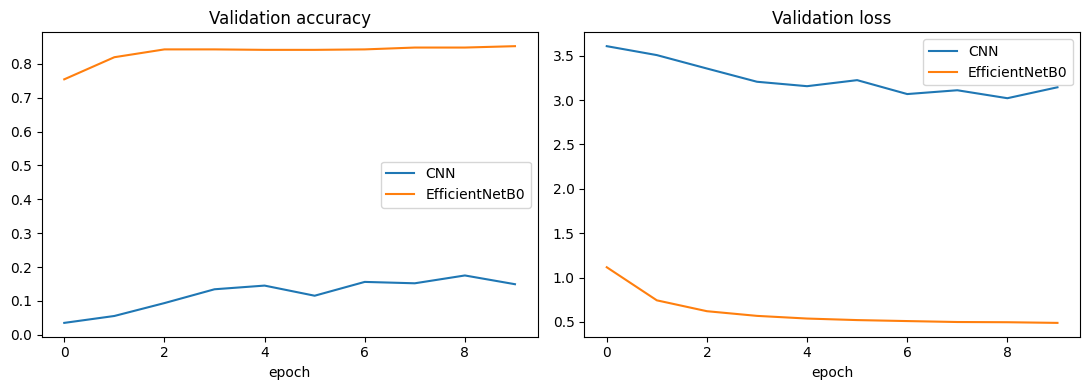

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for h, name in [(hist_cnn, "CNN"), (hist_eff, "EfficientNetB0")]:
    ax[0].plot(h["val_accuracy"], label=name)
    ax[1].plot(h["val_loss"], label=name)
ax[0].set_title("Validation accuracy"); ax[1].set_title("Validation loss")
for a in ax:
    a.set_xlabel("epoch"); a.legend()
plt.tight_layout()
plt.show()